In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/label_mapping.json
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0079.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0018.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0032.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0049.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0215.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0064.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0016.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0114.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0090.jpg

In [5]:
import os

train_path = "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/train"

for cls in sorted(os.listdir(train_path)):
    folder = os.path.join(train_path, cls)

    if os.path.isdir(folder):
        print(cls, len(os.listdir(folder)))

Bacterial Leaf Blight 226
Brown Spot 289
Healthy Rice Leaf 193
Leaf Blast 360
Leaf scald 220
Narrow Brown Leaf Spot 126
Rice Hispa 260
Sheath Blight 352


In [8]:
from PIL import Image
import os

sizes = []

for cls in os.listdir(train_path):
    folder = os.path.join(train_path, cls)

    for img in os.listdir(folder):
        path = os.path.join(folder, img)

        image = Image.open(path)
        sizes.append(image.size)

print(sizes[:20])

[(1600, 1200), (1200, 1600), (1600, 1200), (1600, 1200), (1200, 1600), (1200, 1600), (1200, 1253), (1200, 1600), (1056, 1408), (1600, 1200), (1200, 1600), (1600, 1200), (1600, 1200), (1200, 1600), (1200, 1600), (1600, 1200), (1600, 1200), (1200, 1600), (1200, 1600), (1200, 1600)]


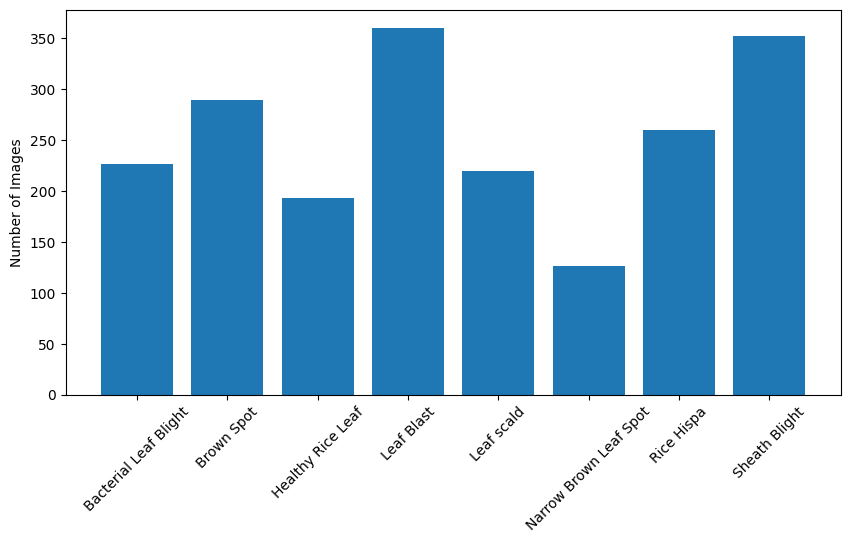

In [9]:
import os
import matplotlib.pyplot as plt

classes = []
counts = []

for cls in sorted(os.listdir(train_path)):
    folder = os.path.join(train_path, cls)

    classes.append(cls)
    counts.append(len(os.listdir(folder)))

plt.figure(figsize=(10,5))
plt.bar(classes, counts)
plt.xticks(rotation=45)
plt.ylabel("Number of Images")
plt.show()

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

from PIL import Image
from PIL import ImageOps

from skimage.feature import hog
from skimage.feature import local_binary_pattern

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

from sklearn.svm import SVC

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import VotingClassifier

In [ ]:
TRAIN_DIR = "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/train"

TEST_DIR = "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup"

IMAGE_SIZE = 224

In [ ]:
# ============================================================
# RICE LEAF DISEASE CLASSIFICATION
# Traditional Machine Learning Pipeline
#
# Dataset:
# - 8 rice leaf disease classes
# - 2026 training images
# - 300 test images
#
# Methods:
# - HOG
# - LBP
# - Color Histogram
#
# Models:
# - SVM
# - KNN
# - Decision Tree
# - Logistic Regression
# - Voting Ensemble
#
# Author: Your Name
# ============================================================


# ============================================================
# IMPORT LIBRARIES
# ============================================================

import os
import cv2
import json
import hashlib
import warnings

import numpy as np
import pandas as pd

from PIL import Image
from PIL import ImageOps

from tqdm import tqdm

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ============================================================
# CONFIGURATION
# ============================================================

# Training folder
TRAIN_DIR = "dataset/train"

# Test folder
TEST_DIR = "dataset/test_warmup"

# Label mapping file
LABEL_MAPPING_FILE = "dataset/label_mapping.json"

# Final image size
IMAGE_SIZE = 224

# Random seed
RANDOM_STATE = 42

# Cache folder
CACHE_DIR = "cache"

# Output folder
OUTPUT_DIR = "output"


# ============================================================
# CREATE REQUIRED FOLDERS
# ============================================================

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# LOAD LABEL MAPPING
# ============================================================

def load_label_mapping():
    """
    Load label mapping from json file.

    Returns
    -------
    dict
        Example:
        {
            "Bacterial Leaf Blight":0,
            ...
        }
    """

    with open(LABEL_MAPPING_FILE, "r", encoding="utf-8") as f:
        mapping = json.load(f)

    return mapping


# ============================================================
# IMAGE PREPROCESSING
# ============================================================

def resize_with_padding(
        image: Image.Image,
        target_size: int = IMAGE_SIZE
):
    """
    Resize image while preserving aspect ratio.

    Add black padding to obtain
    a square image.

    Example

        1600 x 1200

            ↓

        224 x 168

            ↓

        Padding

            ↓

        224 x 224

    Parameters
    ----------
    image : PIL.Image

    target_size : int

    Returns
    -------
    PIL.Image
    """

    image = image.copy()

    image.thumbnail(
        (target_size, target_size),
        Image.Resampling.LANCZOS
    )

    delta_w = target_size - image.size[0]
    delta_h = target_size - image.size[1]

    padding = (
        delta_w // 2,
        delta_h // 2,
        delta_w - delta_w // 2,
        delta_h - delta_h // 2
    )

    image = ImageOps.expand(
        image,
        border=padding,
        fill=(0, 0, 0)
    )

    return image


# ============================================================
# VERIFY IMAGE CAN BE OPENED
# ============================================================

def is_valid_image(image_path: str) -> bool:
    """
    Check whether image is valid.

    Returns
    -------
    bool
    """

    try:

        img = Image.open(image_path)

        img.verify()

        return True

    except Exception:

        return False


# ============================================================
# FIND BROKEN IMAGES
# ============================================================

def find_broken_images(train_dir: str):
    """
    Scan dataset and find broken images.

    Returns
    -------
    list
    """

    broken_images = []

    print("\nScanning broken images...\n")

    for class_name in os.listdir(train_dir):

        class_dir = os.path.join(
            train_dir,
            class_name
        )

        if not os.path.isdir(class_dir):
            continue

        for image_name in tqdm(
                os.listdir(class_dir),
                desc=class_name
        ):

            image_path = os.path.join(
                class_dir,
                image_name
            )

            if not is_valid_image(image_path):

                broken_images.append(
                    image_path
                )

    return broken_images


# ============================================================
# FIND DUPLICATE IMAGES
# ============================================================

def find_duplicate_images(train_dir: str):
    """
    Detect duplicate images using MD5 hash.

    Returns
    -------
    list
    """

    print("\nScanning duplicate images...\n")

    hashes = {}

    duplicates = []

    for class_name in os.listdir(train_dir):

        class_dir = os.path.join(
            train_dir,
            class_name
        )

        if not os.path.isdir(class_dir):
            continue

        for image_name in tqdm(
                os.listdir(class_dir),
                desc=class_name
        ):

            image_path = os.path.join(
                class_dir,
                image_name
            )

            try:

                with open(
                        image_path,
                        "rb"
                ) as f:

                    file_hash = hashlib.md5(
                        f.read()
                    ).hexdigest()

                if file_hash in hashes:

                    duplicates.append(
                        (
                            hashes[file_hash],
                            image_path
                        )
                    )

                else:

                    hashes[file_hash] = image_path

            except Exception:

                pass

    return duplicates


# ============================================================
# DATASET OVERVIEW
# ============================================================

def dataset_overview(train_dir: str):
    """
    Display number of images
    in each class.
    """

    print("\n")
    print("=" * 60)
    print("DATASET OVERVIEW")
    print("=" * 60)

    total_images = 0

    for class_name in sorted(
            os.listdir(train_dir)
    ):

        class_dir = os.path.join(
            train_dir,
            class_name
        )

        if not os.path.isdir(class_dir):
            continue

        count = len(
            os.listdir(class_dir)
        )

        total_images += count

        print(
            f"{class_name:<30} {count:>5}"
        )

    print("-" * 60)

    print(
        f"{'TOTAL':<30} {total_images:>5}"
    )

    print("=" * 60)


# ============================================================
# IMAGE SIZE ANALYSIS
# ============================================================

def analyze_image_sizes(
        train_dir: str
):
    """
    Analyze image resolutions.
    """

    sizes = []

    print(
        "\nAnalyzing image sizes...\n"
    )

    for class_name in os.listdir(
            train_dir
    ):

        class_dir = os.path.join(
            train_dir,
            class_name
        )

        if not os.path.isdir(class_dir):
            continue

        for image_name in tqdm(
                os.listdir(class_dir),
                desc=class_name
        ):

            image_path = os.path.join(
                class_dir,
                image_name
            )

            try:

                img = Image.open(
                    image_path
                )

                sizes.append(
                    img.size
                )

            except Exception:

                pass

    print("\nNumber of images:", len(sizes))

    unique_sizes = pd.Series(
        sizes
    ).value_counts()

    print("\nTop 20 image sizes:\n")

    print(
        unique_sizes.head(20)
    )

    return sizes


# ============================================================
# MAIN TEST FUNCTION
# ============================================================

def run_preprocessing_checks():
    """
    Run all preprocessing checks.
    """

    dataset_overview(
        TRAIN_DIR
    )

    broken_images = find_broken_images(
        TRAIN_DIR
    )

    print(
        f"\nBroken images found: {len(broken_images)}"
    )

    duplicates = find_duplicate_images(
        TRAIN_DIR
    )

    print(
        f"\nDuplicate pairs found: {len(duplicates)}"
    )

    analyze_image_sizes(
        TRAIN_DIR
    )


# ============================================================
# ENTRY POINT
# ============================================================

if __name__ == "__main__":

    print(
        "\nRice Disease Classification Project\n"
    )

    run_preprocessing_checks()

In [ ]:
# ============================================================
# FEATURE EXTRACTION
# ============================================================

from skimage.feature import hog
from skimage.feature import local_binary_pattern


# ============================================================
# HOG CONFIGURATION
# ============================================================

# Number of orientation bins
HOG_ORIENTATIONS = 9

# Size of each cell
HOG_PIXELS_PER_CELL = (8, 8)

# Number of cells in one block
HOG_CELLS_PER_BLOCK = (2, 2)


# ============================================================
# LBP CONFIGURATION
# ============================================================

LBP_POINTS = 8
LBP_RADIUS = 1


# ============================================================
# COLOR HISTOGRAM CONFIGURATION
# ============================================================

COLOR_BINS = 8


# ============================================================
# EXTRACT HOG FEATURE
# ============================================================

def extract_hog(image: Image.Image) -> np.ndarray:
    """
    Extract Histogram of Oriented Gradients (HOG).

    Parameters
    ----------
    image : PIL.Image

    Returns
    -------
    np.ndarray
        HOG feature vector.
    """

    # Resize về cùng kích thước
    image = resize_with_padding(image)

    # RGB -> Gray
    gray = np.array(image.convert("L"))

    feature = hog(
        gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        visualize=False,
        feature_vector=True
    )

    return feature.astype(np.float32)


# ============================================================
# EXTRACT LBP FEATURE
# ============================================================

def extract_lbp(image: Image.Image) -> np.ndarray:
    """
    Extract Local Binary Pattern histogram.

    Parameters
    ----------
    image : PIL.Image

    Returns
    -------
    np.ndarray
    """

    image = resize_with_padding(image)

    gray = np.array(image.convert("L"))

    lbp = local_binary_pattern(
        gray,
        P=LBP_POINTS,
        R=LBP_RADIUS,
        method="uniform"
    )

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, LBP_POINTS + 3),
        range=(0, LBP_POINTS + 2)
    )

    histogram = histogram.astype(np.float32)

    histogram /= (histogram.sum() + 1e-8)

    return histogram


# ============================================================
# EXTRACT RGB COLOR HISTOGRAM
# ============================================================

def extract_color_histogram(image: Image.Image) -> np.ndarray:
    """
    Extract normalized RGB histogram.

    Parameters
    ----------
    image : PIL.Image

    Returns
    -------
    np.ndarray
    """

    image = resize_with_padding(image)

    image = np.array(image)

    histogram = cv2.calcHist(
        [image],
        [0, 1, 2],
        None,
        [COLOR_BINS, COLOR_BINS, COLOR_BINS],
        [0, 256, 0, 256, 0, 256]
    )

    histogram = cv2.normalize(
        histogram,
        histogram
    ).flatten()

    return histogram.astype(np.float32)


# ============================================================
# COMBINE ALL FEATURES
# ============================================================

def extract_feature(image: Image.Image) -> np.ndarray:
    """
    Combine

    HOG
        +
    LBP
        +
    Color Histogram

    into one feature vector.

    Returns
    -------
    np.ndarray
    """

    hog_feature = extract_hog(image)

    lbp_feature = extract_lbp(image)

    color_feature = extract_color_histogram(image)

    feature = np.concatenate(

        [
            hog_feature,
            lbp_feature,
            color_feature
        ]

    )

    return feature.astype(np.float32)


# ============================================================
# DISPLAY FEATURE DIMENSION
# ============================================================

def feature_information():
    """
    Print feature dimension.
    """

    dummy = Image.new(
        "RGB",
        (IMAGE_SIZE, IMAGE_SIZE),
        color="white"
    )

    hog_feature = extract_hog(dummy)

    lbp_feature = extract_lbp(dummy)

    color_feature = extract_color_histogram(dummy)

    feature = extract_feature(dummy)

    print("\n")
    print("=" * 60)
    print("FEATURE INFORMATION")
    print("=" * 60)

    print(f"HOG Feature           : {len(hog_feature)}")

    print(f"LBP Feature           : {len(lbp_feature)}")

    print(f"Color Histogram       : {len(color_feature)}")

    print("-" * 60)

    print(f"Total Feature Length  : {len(feature)}")

    print("=" * 60)


# ============================================================
# VISUALIZE FEATURE EXTRACTION
# ============================================================

def visualize_feature_example(image_path: str):
    """
    Display original image
    and print feature length.

    Parameters
    ----------
    image_path : str
    """

    image = Image.open(image_path).convert("RGB")

    resized = resize_with_padding(image)

    feature = extract_feature(image)

    plt.figure(figsize=(5, 5))

    plt.imshow(resized)

    plt.axis("off")

    plt.title("Resize + Padding")

    plt.show()

    print("\nFeature Vector Shape")

    print(feature.shape)

    print()

    print(feature[:30])


# ============================================================
# TEST FEATURE EXTRACTION
# ============================================================

def test_feature_extraction():
    """
    Test feature extraction.

    This function only runs
    one image.
    """

    print("\n")

    feature_information()

    # Lấy ảnh đầu tiên trong dataset

    for class_name in sorted(os.listdir(TRAIN_DIR)):

        class_dir = os.path.join(
            TRAIN_DIR,
            class_name
        )

        if not os.path.isdir(class_dir):
            continue

        image_name = os.listdir(class_dir)[0]

        image_path = os.path.join(
            class_dir,
            image_name
        )

        print("\nExample Image")

        print(image_path)

        visualize_feature_example(image_path)

        break